# Ames Campus Network — Post-Processing
Removes leaf / dead-end junctions from the manually-pruned SUMO network.

**Input:**  `ames_campus.net.xml`  (post-netedit surgery)
**Output:** `ames_campus_final.net.xml`

A leaf junction has undirected degree < 2 — it is a dead-end road segment that
serves no routing purpose.  Removal is iterated until no degree-1 nodes remain.


In [1]:
import sumolib
import networkx as nx
import subprocess, os
import xml.etree.ElementTree as ET
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.rcParams.update({'figure.dpi': 130, 'font.size': 11})


## Config
`REGEN = True` re-runs the removal and writes `ames_campus_final.net.xml`.
`False` loads the existing output for visualisation only.


In [2]:
REGEN = False


## Input network — post-surgery state (`ames_campus.net.xml`)


In [3]:
net_in   = sumolib.net.readNet('ames_campus.net.xml')
junc_in  = [j for j in net_in.getNodes() if j.getType() != 'internal']
edge_in  = [e for e in net_in.getEdges() if not e.getID().startswith(':')]

G = nx.Graph()
for j in junc_in:
    G.add_node(j.getID(), x=j.getCoord()[0], y=j.getCoord()[1])
for e in edge_in:
    u, v = e.getFromNode().getID(), e.getToNode().getID()
    if u in G and v in G:
        G.add_edge(u, v)

deg_dist = Counter(d for _, d in G.degree())
leaf_nodes = {n for n in G if G.degree(n) < 2}

print(f'Input: {G.number_of_nodes()} junctions, {G.number_of_edges()} undirected edges')
print(f'Leaf junctions (deg < 2): {len(leaf_nodes)}')
print('Degree distribution:', dict(sorted(deg_dist.items())))


Input: 51 junctions, 65 undirected edges
Leaf junctions (deg < 2): 18
Degree distribution: {1: 18, 3: 21, 4: 11, 5: 1}


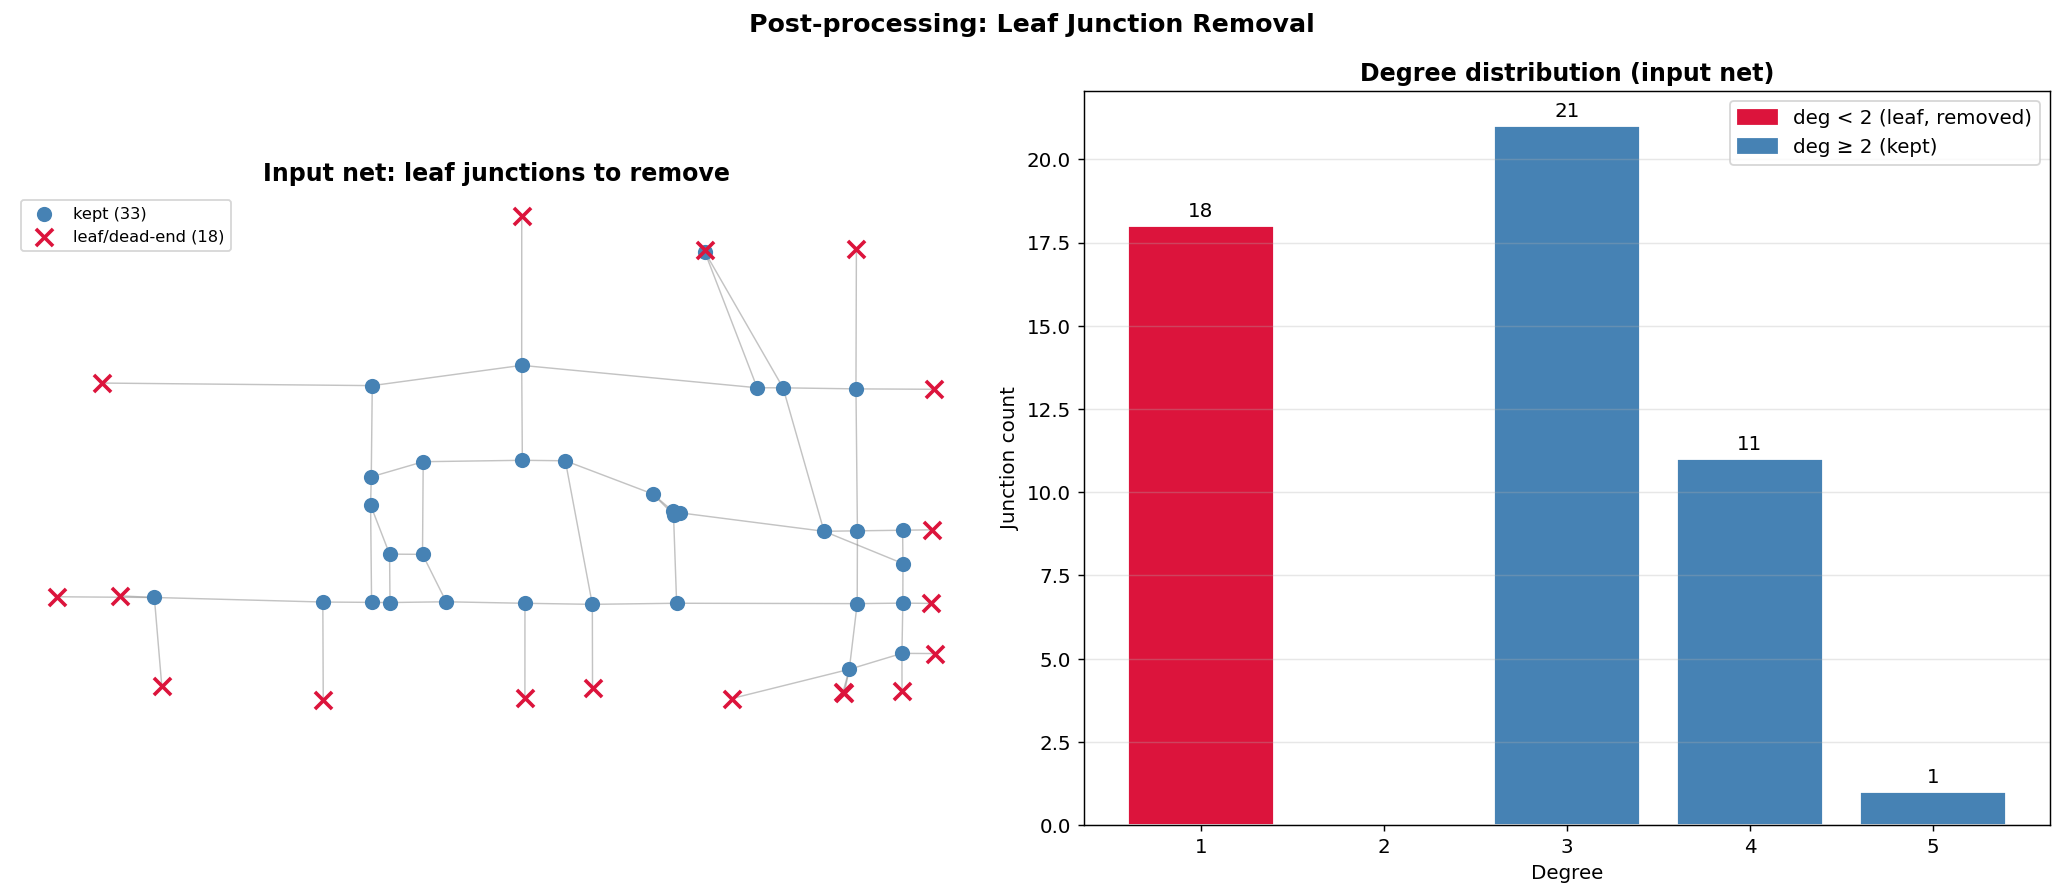

In [4]:
pos = {n: (G.nodes[n]['x'], G.nodes[n]['y']) for n in G.nodes()}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Map: leaf nodes highlighted
ax = axes[0]
for u, v in G.edges():
    ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
            '-', color='#888', lw=0.8, alpha=0.5, zorder=1)
kept  = [n for n in G if n not in leaf_nodes]
remov = list(leaf_nodes)
ax.scatter([pos[n][0] for n in kept],  [pos[n][1] for n in kept],
           s=55, color='steelblue', label=f'kept ({len(kept)})', zorder=3)
ax.scatter([pos[n][0] for n in remov], [pos[n][1] for n in remov],
           s=90, color='crimson', marker='x', linewidths=2,
           label=f'leaf/dead-end ({len(remov)})', zorder=4)
ax.legend(fontsize=9)
ax.set_title('Input net: leaf junctions to remove', fontweight='bold')
ax.set_aspect('equal'); ax.axis('off')

# Degree distribution
ax2 = axes[1]
degs   = sorted(deg_dist.keys())
colors = ['crimson' if d < 2 else 'steelblue' for d in degs]
bars   = ax2.bar(degs, [deg_dist[d] for d in degs], color=colors, edgecolor='white')
for bar, d in zip(bars, degs):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.15,
             str(deg_dist[d]), ha='center', va='bottom')
ax2.set_xlabel('Degree'); ax2.set_ylabel('Junction count')
ax2.set_title('Degree distribution (input net)', fontweight='bold')
ax2.legend(handles=[mpatches.Patch(color='crimson',   label='deg < 2 (leaf, removed)'),
                    mpatches.Patch(color='steelblue', label='deg ≥ 2 (kept)')])
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('Post-processing: Leaf Junction Removal', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('viz_post_input.png', bbox_inches='tight'); plt.show()


## Leaf removal
Iteratively removes any junction with undirected degree < 2 until none remain.
Removing a leaf can expose its neighbour as a new leaf, so the process repeats.


In [5]:
def remove_leaf_nodes(G):
    G = G.copy()
    changed = True
    while changed:
        changed = False
        for node in list(G.nodes()):
            if G.degree(node) < 2:
                G.remove_node(node)
                changed = True
                break
    return G

G_clean   = remove_leaf_nodes(G)
surviving  = set(G_clean.nodes())
removed    = set(G.nodes()) - surviving

print(f'Removed {len(removed)} leaf junctions')
print(f'Output: {G_clean.number_of_nodes()} junctions, {G_clean.number_of_edges()} undirected edges')


Removed 20 leaf junctions
Output: 31 junctions, 45 undirected edges


In [6]:
if REGEN:
    full_pos = {j.getID(): j.getCoord() for j in junc_in}

    nod_root = ET.Element('nodes')
    for nid in surviving:
        x, y = full_pos[nid]
        ET.SubElement(nod_root, 'node', id=nid, x=f'{x:.2f}', y=f'{y:.2f}', type='priority')
    ET.ElementTree(nod_root).write('tmp_nodes.xml', encoding='unicode', xml_declaration=True)

    edg_root = ET.Element('edges')
    for e in edge_in:
        u, v = e.getFromNode().getID(), e.getToNode().getID()
        if u not in surviving or v not in surviving:
            continue
        e_elem = ET.SubElement(edg_root, 'edge')
        e_elem.set('id',       e.getID())
        e_elem.set('from',     u)
        e_elem.set('to',       v)
        e_elem.set('numLanes', str(e.getLaneNumber()))
        e_elem.set('speed',    str(e.getSpeed()))
        e_elem.set('priority', str(e.getPriority()))
        shape = e.getShape()
        if shape:
            e_elem.set('shape', ' '.join(f'{sx:.2f},{sy:.2f}' for sx, sy in shape))
    ET.ElementTree(edg_root).write('tmp_edges.xml', encoding='unicode', xml_declaration=True)

    subprocess.run([
        'netconvert',
        '--node-files',  'tmp_nodes.xml',
        '--edge-files',  'tmp_edges.xml',
        '--output-file', 'ames_campus_final.net.xml',
        '--no-turnarounds',
    ], check=True)
    for f in ('tmp_nodes.xml', 'tmp_edges.xml'):
        os.remove(f)
    print('Done — ames_campus_final.net.xml written')


## Output network (`ames_campus_final.net.xml`)


Output: 31 junctions, 86 directed edges


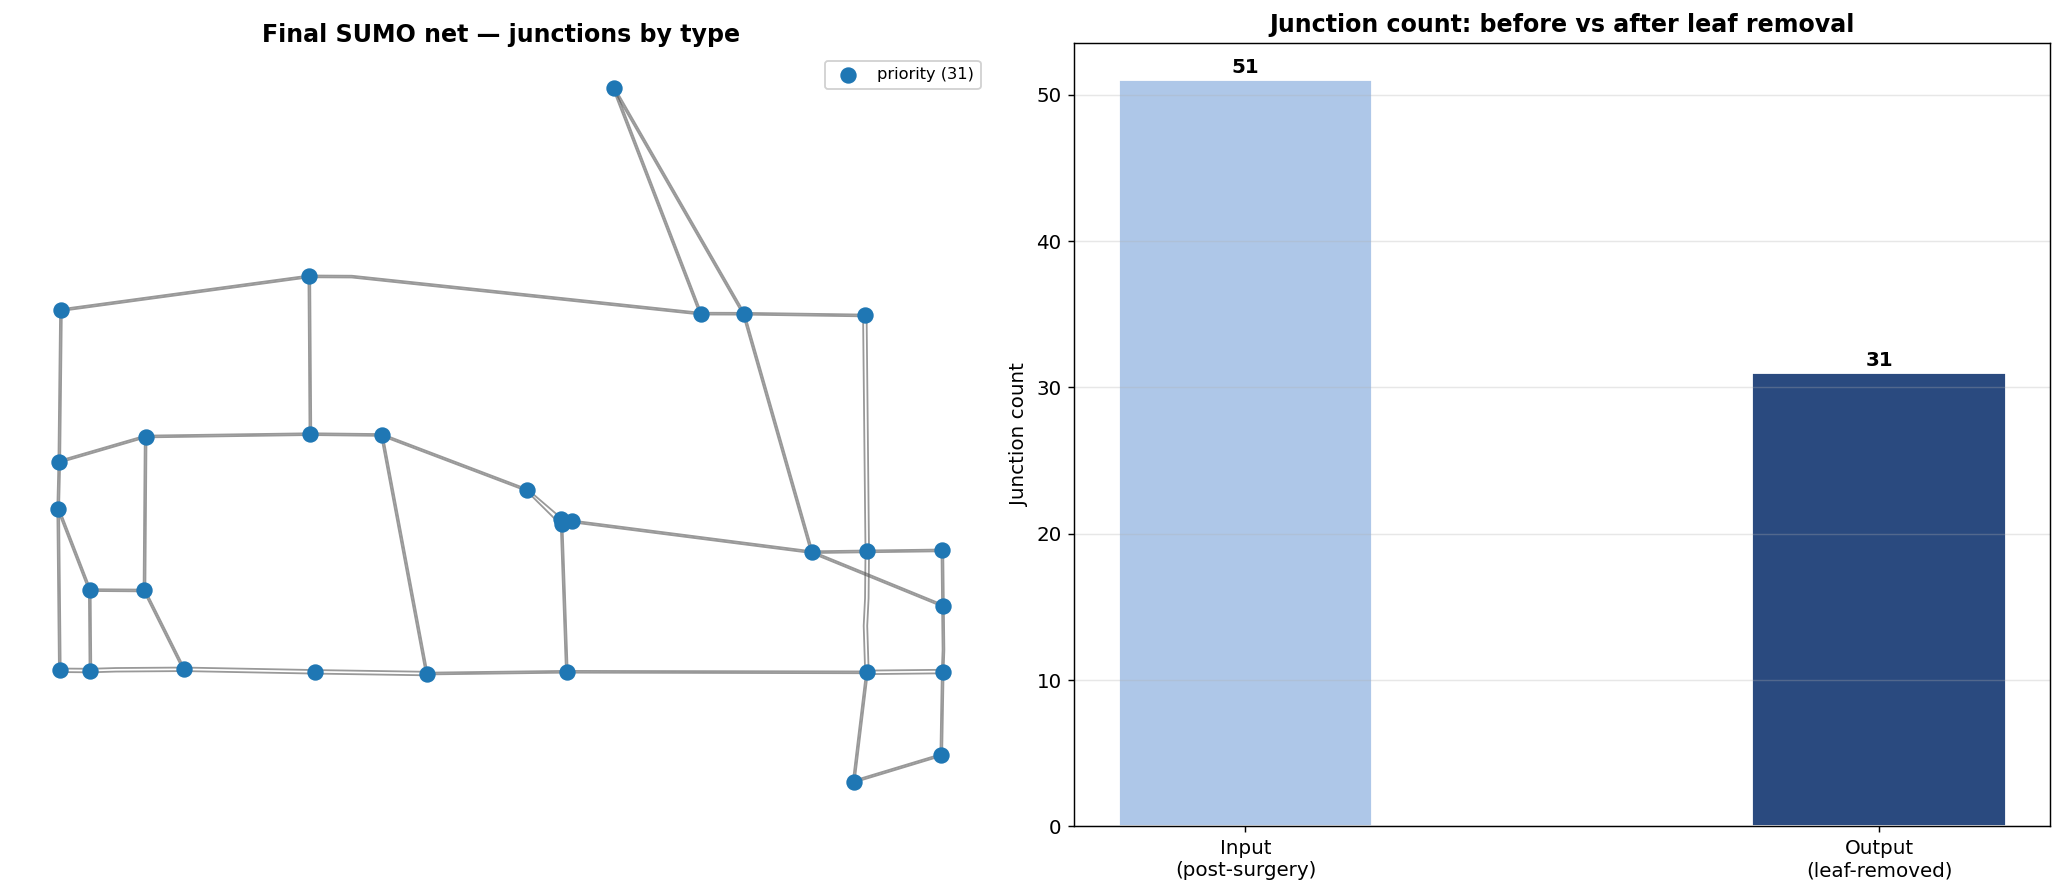

In [7]:
net_out   = sumolib.net.readNet('ames_campus_final.net.xml')
junc_out  = [j for j in net_out.getNodes() if j.getType() != 'internal']
edge_out  = [e for e in net_out.getEdges() if not e.getID().startswith(':')]
print(f'Output: {len(junc_out)} junctions, {len(edge_out)} directed edges')

cmap        = plt.cm.tab10
junc_types  = sorted(set(j.getType() for j in junc_out))
type_color  = {t: cmap(i) for i, t in enumerate(junc_types)}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Map
ax = axes[0]
for e in edge_out:
    sh = e.getShape()
    if len(sh) >= 2:
        xs, ys = zip(*sh)
        ax.plot(xs, ys, '-', color='#555', lw=1.0, alpha=0.6, zorder=1)
for jtype in junc_types:
    js = [j for j in junc_out if j.getType() == jtype]
    ax.scatter([j.getCoord()[0] for j in js], [j.getCoord()[1] for j in js],
               s=65, color=type_color[jtype],
               label=f'{jtype} ({len(js)})', zorder=3)
ax.legend(fontsize=9, framealpha=0.9)
ax.set_title('Final SUMO net — junctions by type', fontweight='bold')
ax.set_aspect('equal'); ax.axis('off')

# Before vs after bar chart
ax2 = axes[1]
stages = ['Input\n(post-surgery)', 'Output\n(leaf-removed)']
n_j    = [G.number_of_nodes(),       G_clean.number_of_nodes()]
x = np.arange(2); w = 0.4
bars = ax2.bar(x, n_j, w, color=['#aec7e8', '#2a4a7f'], edgecolor='white')
for bar, v in zip(bars, n_j):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
             str(v), ha='center', va='bottom', fontweight='bold')
ax2.set_xticks(x); ax2.set_xticklabels(stages)
ax2.set_ylabel('Junction count'); ax2.grid(axis='y', alpha=0.3)
ax2.set_title('Junction count: before vs after leaf removal', fontweight='bold')

plt.tight_layout()
plt.savefig('viz_post_final.png', bbox_inches='tight'); plt.show()


## Summary


In [8]:
rows = [
    ('Junctions (input)',          G.number_of_nodes()),
    ('Directed edges (input)',     len(edge_in)),
    ('Leaf junctions removed',     len(removed)),
    ('Junctions (output)',         G_clean.number_of_nodes()),
    ('Directed edges (output)',    len(edge_out)),
]
w = max(len(r[0]) for r in rows)
print('Post-processing summary')
print('─' * (w + 12))
for label, val in rows:
    print(f'  {label:<{w}}  {val}')


Post-processing summary
───────────────────────────────────
  Junctions (input)        51
  Directed edges (input)   122
  Leaf junctions removed   20
  Junctions (output)       31
  Directed edges (output)  86
